# TF-IDF Based Classification

## Ecommerce Product Analysis

### Objective
The objective of this notebook is to investigate whether adding TF-IDF features extracted from book descriptions improves classification performance.

### Methodology
1. Load the cleaned dataset.
2. Prepare numerical, categorical, and textual features.
3. Build a baseline classification model.
4. Integrate TF-IDF using a machine learning pipeline.
5. Compare model performance before and after adding TF-IDF features.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, f1_score

In [2]:
df = pd.read_csv("../data/books_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1000, 17)


,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews,has_description,description_length,description_length_log,description_length_capped
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-i...,51.77,3,In stock,22,Poetry,a897fe39b1053632,It's hard to imagine a world without A Light i...,0.0,51.77,51.77,0,True,1017,6.925595,1017.0
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-t...,53.74,1,In stock,20,Historical Fiction,90fa61229261140a,"""Erotic and absorbing...Written with starling ...",0.0,53.74,53.74,0,True,1029,6.937314,1029.0
2,Soumission,https://books.toscrape.com/catalogue/soumissio...,50.10,1,In stock,20,Fiction,6957f44c3847a760,"Dans une France assez proche de la nÃ´tre, un ...",0.0,50.10,50.10,0,True,1136,7.036148,1136.0
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-obj...,47.82,4,In stock,20,Mystery,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL across her hear...",0.0,47.82,47.82,0,True,1647,7.407318,1647.0
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a...,54.23,5,In stock,20,History,4165285e1663650f,From a renowned historian comes a groundbreaki...,0.0,54.23,54.23,0,True,1969,7.585789,1969.0


## Prepare the classification target

In [3]:
df_ml = df.copy()

def assign_rating_class(rating):
    if rating <= 2:
        return "Low"
    elif rating == 3:
        return "Medium"
    else:
        return "High"

df_ml["rating_class"] = df_ml["star_rating"].apply(assign_rating_class)

print("Rating classes created!")
print(df_ml["rating_class"].value_counts())

Rating classes created!
rating_class
Low       422
High      375
Medium    203
Name: count, dtype: int64


## Select input features

In [4]:
features = [
    "price",
    "stock_quantity",
    "category",
    "has_description",
    "description_length_log",
    "description"
]

X = df_ml[features].copy()
y = df_ml["rating_class"].copy()

X["description"] = X["description"].fillna("").astype(str)

print("Input features:")
print(X.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Input features:
   price  stock_quantity            category  has_description  \
0  51.77              22              Poetry             True   
1  53.74              20  Historical Fiction             True   
2  50.10              20             Fiction             True   
3  47.82              20             Mystery             True   
4  54.23              20             History             True   

   description_length_log                                        description  
0                6.925595  It's hard to imagine a world without A Light i...  
1                6.937314  "Erotic and absorbing...Written with starling ...  
2                7.036148  Dans une France assez proche de la nÃ´tre, un ...  
3                7.407318  WICKED above her hipbone, GIRL across her hear...  
4                7.585789  From a renowned historian comes a groundbreaki...  

Feature shape: (1000, 6)
Target shape: (1000,)


##  Split the dataset

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 6)
Testing data: (200, 6)


In [6]:
# Remove description to create the original baseline features
X_train_base = X_train.drop(columns=["description"])
X_test_base = X_test.drop(columns=["description"])

numeric_features = [
    "price",
    "stock_quantity",
    "description_length_log",
    "has_description"
]

categorical_features = ["category"]

baseline_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

baseline_model = Pipeline([
    ("preprocessing", baseline_preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

baseline_model.fit(X_train_base, y_train)

print("Baseline Random Forest trained successfully!")

Baseline Random Forest trained successfully!


## Evaluate the baseline model

In [7]:
y_pred_base = baseline_model.predict(X_test_base)

baseline_accuracy = accuracy_score(y_test, y_pred_base)
baseline_f1 = f1_score(y_test, y_pred_base, average="macro")

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Macro F1-Score:", round(baseline_f1, 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_base, zero_division=0))

Baseline Accuracy: 0.42
Baseline Macro F1-Score: 0.3855

Classification Report:

              precision    recall  f1-score   support

        High       0.43      0.44      0.43        75
         Low       0.42      0.51      0.46        84
      Medium       0.40      0.20      0.26        41

    accuracy                           0.42       200
   macro avg       0.42      0.38      0.39       200
weighted avg       0.42      0.42      0.41       200



## Build the TF-IDF classification model

In [8]:
tfidf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("text", TfidfVectorizer(max_features=100, stop_words="english"), "description")
    ]
)

tfidf_model = Pipeline([
    ("preprocessing", tfidf_preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

tfidf_model.fit(X_train, y_train)

print("TF-IDF Random Forest trained successfully!")

TF-IDF Random Forest trained successfully!


## Evaluate the TF-IDF model

In [9]:
y_pred_tfidf = tfidf_model.predict(X_test)

tfidf_accuracy = accuracy_score(y_test, y_pred_tfidf)
tfidf_f1 = f1_score(y_test, y_pred_tfidf, average="macro")

print("TF-IDF Accuracy:", round(tfidf_accuracy, 4))
print("TF-IDF Macro F1-Score:", round(tfidf_f1, 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_tfidf, zero_division=0))

TF-IDF Accuracy: 0.41
TF-IDF Macro F1-Score: 0.3009

Classification Report:

              precision    recall  f1-score   support

        High       0.37      0.43      0.40        75
         Low       0.44      0.60      0.51        84
      Medium       0.00      0.00      0.00        41

    accuracy                           0.41       200
   macro avg       0.27      0.34      0.30       200
weighted avg       0.32      0.41      0.36       200



## Compare baseline and TF-IDF models

In [10]:
comparison_df = pd.DataFrame({
    "Model": ["Baseline (Original Features)", "With TF-IDF"],
    "Accuracy": [baseline_accuracy, tfidf_accuracy],
    "Macro F1-Score": [baseline_f1, tfidf_f1]
})

comparison_df

,Model,Accuracy,Macro F1-Score
0,Baseline (Original Features),0.42,0.385466
1,With TF-IDF,0.41,0.300892


## Important observation:
The TF-IDF model failed to correctly predict any Medium-class books. This is why its Macro F1-score dropped significantly.

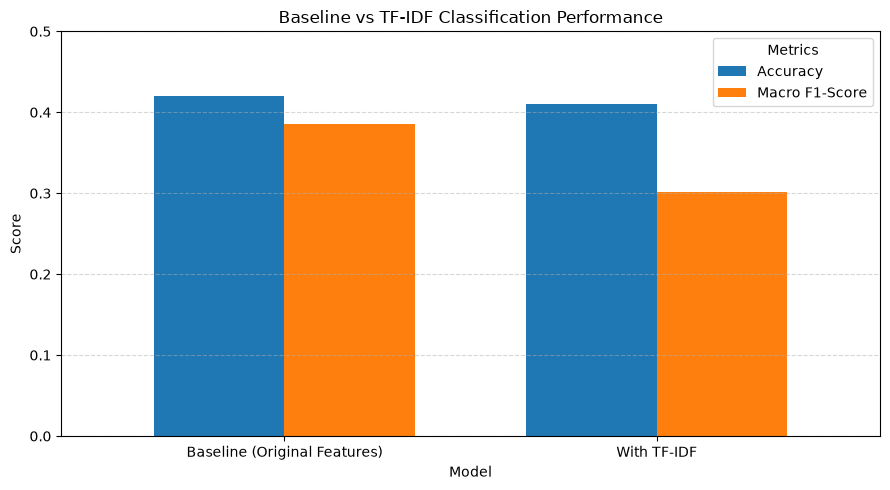

In [11]:
comparison_df.set_index("Model")[["Accuracy", "Macro F1-Score"]].plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 0.5),
    width=0.7
)

plt.title("Baseline vs TF-IDF Classification Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Conclusion

The baseline Random Forest model achieved an accuracy of 42% and a macro F1-score of 0.3855. After adding TF-IDF features extracted from book descriptions, accuracy decreased slightly to 41%, while the macro F1-score dropped to 0.3009.

This shows that TF-IDF did not improve classification performance in this experiment. The TF-IDF model also failed to correctly classify any books in the Medium rating class.

Although the descriptions contain useful textual information, these features did not provide enough additional information to improve the model's predictions. Further experiments with different TF-IDF settings and classification models may produce better results.